# Lateral Bending of Beams

Bending of beams causes compression on one side and tension on the other. The neutral axis is the line within the beam's cross-section where there is no longitudinal stress during bending. The bending moment (M) at a section of the beam is related to the deflection $\omega$ of the beam at that section by the flexural rigidity (EI):
$$M = EI \frac{d^2 \omega}{dx^2}$$

Where:
- $E$ is the Young's modulus of the material
- $I$ is the second moment of area of the beam's cross-section
- $\omega$ is the deflection of the beam at a distance $x$ along its length
- $M$ is the bending moment at that section

relationship table for deflection, slope, bending moment, shear force, and distributed load:
| Quantity         | Symbol | Relationship to Deflection ($\omega$) |
|------------------|--------|---------------------------------------|
| Deflection       | $\omega$ | $\omega$ (itself)                     |
| Slope            | $\theta$ | $\theta = \frac{d\omega}{dx}$         |
| Bending Moment    | $M$     | $M = EI \frac{d^2 \omega}{dx^2}$     |
| Shear Force       | $V$     | $V = EI \frac{d^3 \omega}{dx^3}$     |
| Distributed Load | $w$     | $w = EI \frac{d^4 \omega}{dx^4}$     |

# Bending Stress Formula
The bending stress ($\sigma$) at a distance $y$ from the neutral axis is given by:
$$\sigma = \frac{My}{I}$$

Where:
- $\sigma$ is the bending stress at a distance $y$ from the neutral axis
- $M$ is the bending moment at that section
- $y$ is the distance from the neutral axis to the point of interest
- $I$ is the second moment of area of the beam's cross-section

Iyy = 2.0458e-06 m^4
Max bending stress: 26.9 MPa
Safety factor: 9.30


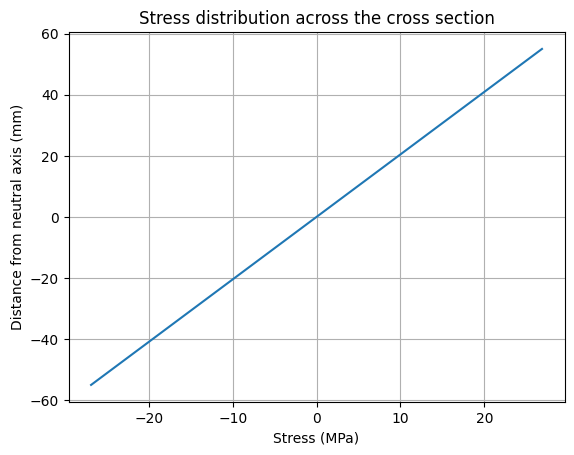

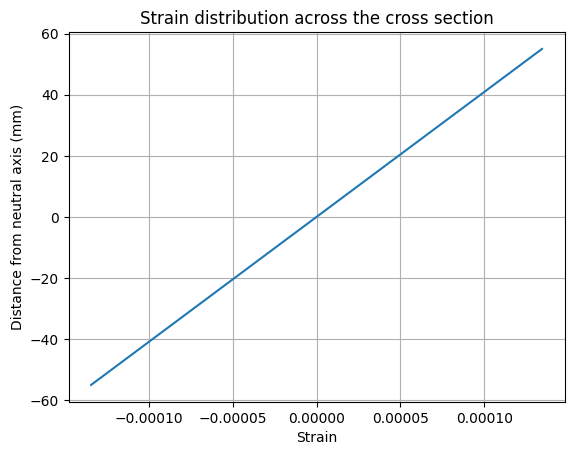

In [1]:
# create a beam of a certain length and cross section (SI units: m, N, Pa)
from engtoolkit.structural import beam, I_beam
from engtoolkit.materials import get_material
import numpy as np
import matplotlib.pyplot as plt

# I-beam: flange 50 x 5 mm, web 100 x 8 mm
shape = I_beam(flange_width=0.050, flange_thickness=0.005, web_height=0.100, web_thickness=0.008)
material = get_material("Steel")
b = beam(material, 2, shape)
print(f"Iyy = {shape.Iyy:.4e} m^4")

moment = 1000  # N.m
sigma_y = material.yield_strength
c = shape.wh / 2 + shape.ft  # distance from neutral axis to outer fibre [m]

# stress distribution
y = np.linspace(-c, c, 100)
sigma = moment * y / shape.Iyy  # Pa

sigma_max = np.max(np.abs(sigma))
SF = sigma_y / sigma_max
print(f"Max bending stress: {sigma_max/1e6:.1f} MPa")
print(f"Safety factor: {SF:.2f}")

# strain distribution
epsilon = sigma / material.E

# plotting distribution of stress against distance from neutral axis
plt.plot(sigma / 1e6, y * 1000)
plt.xlabel("Stress (MPa)")
plt.ylabel("Distance from neutral axis (mm)")
plt.title("Stress distribution across the cross section")
plt.grid()
plt.show()

# strain distribution
plt.plot(epsilon, y * 1000)
plt.xlabel("Strain")
plt.ylabel("Distance from neutral axis (mm)")
plt.title("Strain distribution across the cross section")
plt.grid()
plt.show()
